In [1]:
# ==========================================
# DISK SPACE CLEANUP: REMOVE STALE CHECKPOINTS
# ==========================================
import os, glob

print("Cleaning up stale checkpoint files in /kaggle/working...")
for f in glob.glob("/kaggle/working/*.pth"):
    # Keep only files explicitly marked as 'best' or 'final'
    if "final" not in f and "best" not in f:
        try:
            os.remove(f)
            print(f"🗑️ Removed stale file: {os.path.basename(f)}")
        except Exception as e:
            print(f"Could not remove {f}: {e}")

print("✅ Disk cleanup complete. Ready for execution.")

Cleaning up stale checkpoint files in /kaggle/working...
✅ Disk cleanup complete. Ready for execution.


# CADET: Compression-Aware Deepfake Explainability Technology
**Robustness Hardening via Adversarial Training (ART)**

This notebook implements the training and evaluation pipeline for a bimodal deepfake detector. It includes:
1. Cross-dataset balancing and social media compression simulation.
2. Clean baseline training using an XceptionNet backbone.
3. Adversarial Robustness Training (ART) using dynamic Fast Gradient Sign Method (FGSM) to prevent artifact overfitting.
4. Multi-epsilon robustness evaluation and Grad-CAM visualization.

In [2]:
# ==========================================
# CELL 1: IMPORTS & DEPENDENCIES
# ==========================================
import os
import gc
import time
import copy
import glob
import random

# Image processing and data handling
import cv2
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch and Deep Learning
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import timm

# Utilities
from tqdm import tqdm
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve

print("✅ All dependencies imported successfully.")

✅ All dependencies imported successfully.


In [3]:
# ==========================================
# CELL 2: HARDWARE CONFIGURATION
# ==========================================
# Detect hardware accelerator
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"✅ Using device: {device}")

# Kaggle GPU Optimizations
if torch.cuda.is_available():
    print(f"🖥️ GPU Name: {torch.cuda.get_device_name(0)}")
    
    # Flush residual memory to prevent Out-Of-Memory (OOM) errors
    torch.cuda.empty_cache()
    
    # Enable cuDNN benchmarking to accelerate CNN training for fixed input sizes (299x299)
    torch.backends.cudnn.benchmark = True

✅ Using device: cuda
🖥️ GPU Name: Tesla T4


In [4]:
# ==========================================
# CELL 3: COMPRESSION-BASED PREPROCESSING
# ==========================================
def apply_social_media_compression(img_bgr):
    """
    Simulates the aggressive media compression pipeline typical of social networks.
    Matches the CADET methodology: 
    1. Dynamic Downscale & Upscale (mimicking platform resizing)
    2. Mild Gaussian Blur (simulating loss of fine details)
    3. Heavy JPEG Compression (introducing chroma subsampling artifacts)
    """
    h, w, _ = img_bgr.shape
    
    # Step 1: Dynamic Downscaling and Upscaling
    scale_factor = random.uniform(0.85, 1.0)
    new_h, new_w = max(1, int(h * scale_factor)), max(1, int(w * scale_factor))
    
    img_resized = cv2.resize(img_bgr, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)
    
    # Step 2: Apply a mild Gaussian Blur (70% probability)
    if random.random() < 0.7:
        img_resized = cv2.GaussianBlur(img_resized, (5, 5), 0)
        
    # Step 3: Extreme JPEG Compression with Chroma Subsampling
    quality = random.randint(10, 25)
    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    success, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    
    if not success:
        raise RuntimeError("JPEG compression failed during preprocessing.")
        
    decimg_bgr = cv2.imdecode(encimg, 1)
    
    # Convert back to RGB for PIL / PyTorch compatibility
    return cv2.cvtColor(decimg_bgr, cv2.COLOR_BGR2RGB)

In [5]:
# ==========================================
# CELL 4: BALANCED CROSS-DATASET PIPELINE
# ==========================================
class BalancedDeepfakeDataset(Dataset):
    """
    Custom Dataset that aggregates Celeb-DF, 140k Real/Fake, and FaceForensics++.
    Enforces strict class (Real/Fake) AND source (Dataset) balance to prevent
    the massive 140k dataset from overwhelming the smaller datasets.
    Applies the social media compression pipeline dynamically.
    """
    def __init__(self, split='train', base_dir='/kaggle/input', transform=None, seed=42, compression_prob=0.5):
        self.transform = transform
        self.compression_prob = compression_prob
        self.image_paths = []
        self.labels = []
        self.rng = random.Random(seed)
        
        self._temp_data = {
            'celeb': {0: [], 1: []},
            '140k': {0: [], 1: []},
            'ffpp': {0: [], 1: []}
        }
        
        print(f"[{split.upper()}] Scanning {base_dir} to find datasets...")
        dataset_paths = self._auto_discover_paths(base_dir)
        
        self._load_celebdf(dataset_paths['celeb'], split)
        self._load_140k(dataset_paths['140k'], split)
        self._load_ffpp(dataset_paths['ffpp'], split)
        
        self._balance_and_merge(split)

    def _auto_discover_paths(self, base_dir):
        paths = {'celeb': None, 'ffpp': None, '140k': None}
        for root, dirs, files in os.walk(base_dir):
            if 'Celeb_V2' in dirs and not paths['celeb']:
                paths['celeb'] = os.path.join(root, 'Celeb_V2')
            if 'dataset_processed_split' in dirs and not paths['ffpp']:
                paths['ffpp'] = os.path.join(root, 'dataset_processed_split')
            if 'real-vs-fake' in dirs and not paths['140k']:
                paths['140k'] = os.path.join(root, 'real-vs-fake')
        return paths

    def _add_from_folder(self, dataset_name, folder_path, label):
        if os.path.exists(folder_path):
            for ext in ('*.png', '*.jpg', '*.jpeg'):
                paths = glob.glob(os.path.join(folder_path, ext))
                self._temp_data[dataset_name][label].extend(paths)

    def _load_celebdf(self, base_path, split):
        split_map = {'train': 'Train', 'val': 'Val', 'test': 'Test'}
        target_split = split_map.get(split)
        if base_path and os.path.exists(base_path) and target_split:
            self._add_from_folder('celeb', os.path.join(base_path, target_split, 'real'), 0)
            self._add_from_folder('celeb', os.path.join(base_path, target_split, 'fake'), 1)

    def _load_140k(self, base_path, split):
        split_map = {'train': 'train', 'val': 'valid', 'test': 'test'}
        target_split = split_map.get(split)
        if base_path and os.path.exists(base_path) and target_split:
            self._add_from_folder('140k', os.path.join(base_path, target_split, 'real'), 0)
            self._add_from_folder('140k', os.path.join(base_path, target_split, 'fake'), 1)

    def _load_ffpp(self, base_path, split):
        if base_path:
            split_path = os.path.join(base_path, split)
            if os.path.exists(split_path):
                for class_dir in os.listdir(split_path):
                    dir_path = os.path.join(split_path, class_dir)
                    if os.path.isdir(dir_path):
                        label = 0 if class_dir == 'Real' else 1
                        self._add_from_folder('ffpp', dir_path, label)

    def _balance_and_merge(self, split):
        min_count = float('inf')
        for ds_name, labels in self._temp_data.items():
            count_real = len(labels[0])
            count_fake = len(labels[1])
            if count_real < min_count: min_count = count_real
            if count_fake < min_count: min_count = count_fake
                    
        if min_count == 0:
            print(f"❌ ERROR: One or more categories in {split.upper()} has 0 images. Cannot balance.")
            return

        print(f"[{split.upper()}] Balancing to {min_count} images per category...")
        
        for ds_name, labels in self._temp_data.items():
            for label, paths in labels.items():
                sampled_paths = self.rng.sample(paths, min_count)
                self.image_paths.extend(sampled_paths)
                self.labels.extend([label] * min_count)
        
        combined = list(zip(self.image_paths, self.labels))
        if not combined: return

        self.rng.shuffle(combined)
        self.image_paths, self.labels = zip(*combined)
        self.image_paths = list(self.image_paths)
        self.labels = list(self.labels)
        
        print(f"✅ Final {split} dataset size: {len(self.image_paths)} images ready.\n")

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]
        
        # Load image via CV2 to match the compression pipeline
        img_bgr = cv2.imread(img_path)
        
        # SAFETY CHECK: Catch broken image files in Kaggle datasets
        if img_bgr is None:
            raise RuntimeError(f"Failed to read image at path: {img_path}")
        
        # Dynamically apply our compression function
        if self.rng.random() < self.compression_prob:
            img_rgb = apply_social_media_compression(img_bgr)
        else:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
            
        # Convert to PIL for Torchvision transforms
        img_pil = Image.fromarray(img_rgb)
        
        if self.transform:
            img_tensor = self.transform(img_pil)
            
        return img_tensor, torch.tensor(label, dtype=torch.long)

In [6]:
# ==========================================
# CELL 4: DATA AUGMENTATION & TRANSFORMS
# ==========================================
def get_data_transforms(img_size=299):
    """
    Standard ImageNet transforms for XceptionNet (299x299).
    Includes lightweight spatial and color augmentations for training robustness.
    """
    # Standard ImageNet normalization values
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomCrop(img_size, padding=4, padding_mode='reflect'),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    return train_transform, val_transform

In [7]:
# ==========================================
# CELL 5: INITIALIZE DATASETS & DATALOADERS
# ==========================================
train_transform, val_transform = get_data_transforms(img_size=299)

# Apply dynamic compression simulation ONLY to training data.
# Validation and test data remain pristine for accurate evaluation.
train_dataset = BalancedDeepfakeDataset(split='train', transform=train_transform, seed=42, compression_prob=0.7)
val_dataset   = BalancedDeepfakeDataset(split='val', transform=val_transform, seed=42, compression_prob=0.0)
test_dataset  = BalancedDeepfakeDataset(split='test', transform=val_transform, seed=42, compression_prob=0.0)

# DataLoader setup with pin_memory=True to accelerate CPU-to-GPU data transfer
use_pin_memory = torch.cuda.is_available()

train_loader = DataLoader(
    train_dataset, 
    batch_size=32, 
    shuffle=True, 
    num_workers=2, 
    pin_memory=use_pin_memory
)

val_loader = DataLoader(
    val_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=use_pin_memory
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=32, 
    shuffle=False, 
    num_workers=2, 
    pin_memory=use_pin_memory
)

print(f"✅ DataLoaders initialized (Train: {len(train_dataset)}, Val: {len(val_dataset)}, Test: {len(test_dataset)})")

[TRAIN] Scanning /kaggle/input to find datasets...
[TRAIN] Balancing to 18391 images per category...
✅ Final train dataset size: 110346 images ready.

[VAL] Scanning /kaggle/input to find datasets...
[VAL] Balancing to 4109 images per category...
✅ Final val dataset size: 24654 images ready.

[TEST] Scanning /kaggle/input to find datasets...
[TEST] Balancing to 3944 images per category...
✅ Final test dataset size: 23664 images ready.

✅ DataLoaders initialized (Train: 110346, Val: 24654, Test: 23664)


In [8]:
# ==========================================
# CELL 6: INITIALIZE XCEPTION MODEL
# ==========================================
print("Loading Xception model backbone...")

# Initialize pre-trained Xception network.
# The classification head is modified to output 2 features (Real/Fake).
model = timm.create_model('legacy_xception', pretrained=True, num_classes=2)
model = model.to(device)

print("✅ Model successfully loaded and transferred to GPU.")

Loading Xception model backbone...
Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
✅ Model successfully loaded and transferred to GPU.


In [9]:
# ==========================================
# CELL 7: QUICK VERIFICATION TEST
# ==========================================
print("Running forward pass verification...")

# Fetch one batch to verify shapes
images, labels = next(iter(train_loader))
images = images.to(device)

# Use no_grad() for a simple shape check to save GPU memory
with torch.no_grad():
    outputs = model(images)

print(f"Batch images shape: {images.shape} (Expected: [32, 3, 299, 299])")
print(f"Model outputs shape: {outputs.shape} (Expected: [32, 2])")
print("✅ Verification passed.")

Running forward pass verification...
Batch images shape: torch.Size([32, 3, 299, 299]) (Expected: [32, 3, 299, 299])
Model outputs shape: torch.Size([32, 2]) (Expected: [32, 2])
✅ Verification passed.


In [10]:
# ==========================================
# CELL 8: BATCH LABEL VERIFICATION
# ==========================================
# Fetch one batch to verify the tensor shapes and label distribution
images, labels = next(iter(train_loader))
print(f"Batch images tensor shape: {images.shape}")
print(f"Batch labels:\n{labels}")

# Quick check to ensure the DataLoader is pulling relatively balanced batches
real_count = (labels == 0).sum().item()
fake_count = (labels == 1).sum().item()
print(f"Batch distribution -> Real: {real_count}, Fake: {fake_count}")

Batch images tensor shape: torch.Size([32, 3, 299, 299])
Batch labels:
tensor([0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1,
        1, 0, 1, 1, 0, 0, 1, 1])
Batch distribution -> Real: 9, Fake: 23


In [11]:
# ==========================================
# CELL 9: VISUALIZATION HELPER FUNCTION
# ==========================================
def imshow(inp, title=None):
    """
    Helper function to display a PyTorch tensor as an image.
    Un-normalizes the tensor using ImageNet standards before plotting.
    """
    # Safety check: Ensure tensor is on CPU and detached from the graph
    inp = inp.cpu().detach().numpy().transpose((1, 2, 0))
    
    # Un-normalize using the exact mean and std applied during preprocessing
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(12, 8))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.axis('off')
    plt.show()

Generating sample grid...


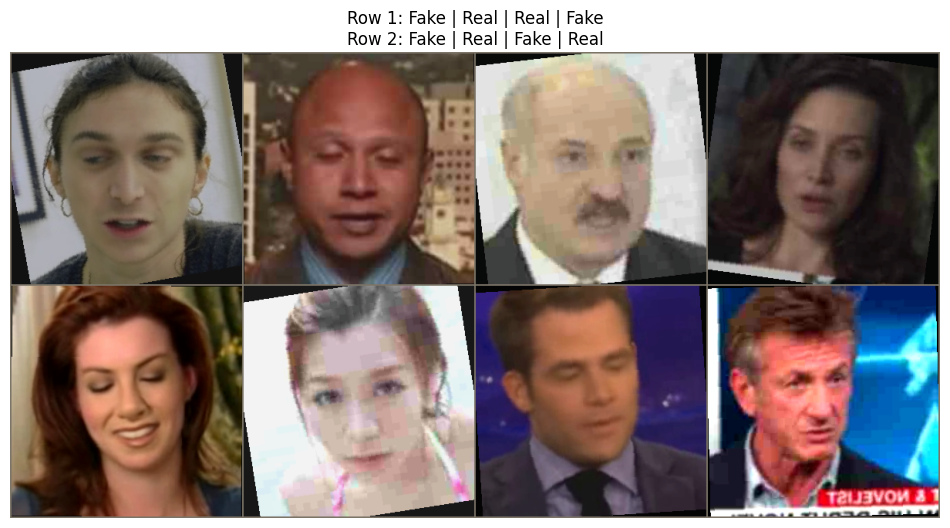

In [12]:
# ==========================================
# CELL 10: VISUALIZE TRAINING BATCH
# ==========================================
print("Generating sample grid...")

# Grab a single batch from the training loader
images, labels = next(iter(train_loader))

# Select the first 8 images for a clean 2x4 grid
num_images_to_show = 8
images_to_show = images[:num_images_to_show]
labels_to_show = labels[:num_images_to_show]

# Create a grid using torchvision
import torchvision # Explicit import for utils
out = torchvision.utils.make_grid(images_to_show, nrow=4)
label_mapping = {0: "Real", 1: "Fake"}

# Format the titles for the plot to align nicely with the 2-row grid
titles = [label_mapping[int(label.item())] for label in labels_to_show]
title_str = "Row 1: " + " | ".join(titles[:4]) + "\nRow 2: " + " | ".join(titles[4:])

imshow(out, title=title_str)

In [13]:
# ==========================================
# CELL 11: SPATIAL DEEPFAKE DETECTOR ARCHITECTURE
# ==========================================
class SpatialDeepfakeDetector(nn.Module):
    """
    Custom Xception-based deepfake detector.
    Uses a modified dense head with Dropout for regularization.
    Outputs 2 logits (Real/Fake) to match standard CrossEntropyLoss.
    """
    def __init__(self, pretrained=True):
        super(SpatialDeepfakeDetector, self).__init__()
        
        # Load Xception backbone 
        self.backbone = timm.create_model('legacy_xception', pretrained=pretrained)
        
        # Replace the classifier head for 2-class output (Real/Fake)
        num_ftrs = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Linear(num_ftrs, 512),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(512, 2)
        )

    def forward(self, x):
        return self.backbone(x)

# Re-initialize the model using the custom class to ensure the new head is applied
print("Initializing custom SpatialDeepfakeDetector...")
model = SpatialDeepfakeDetector(pretrained=True).to(device)
print("✅ Custom model loaded with 2-class output and transferred to GPU.")

Initializing custom SpatialDeepfakeDetector...
✅ Custom model loaded with 2-class output and transferred to GPU.


In [14]:
# ==========================================
# CELL 12: VERIFY CUSTOM ARCHITECTURE
# ==========================================
# Initialize the model and move it to the GPU
model = SpatialDeepfakeDetector(pretrained=True)
model = model.to(device)

# Test the model output shape
images = images.to(device) 
with torch.no_grad():
    outputs = model(images)

print(f"Output tensor shape: {outputs.shape}")
print("If you see torch.Size([32, 2]), the modified Xception model is ready!")

Output tensor shape: torch.Size([32, 2])
If you see torch.Size([32, 2]), the modified Xception model is ready!


In [15]:
# ==========================================
# CELL 13: DEFINE LOSS FUNCTION
# ==========================================
criterion = nn.CrossEntropyLoss()

In [16]:
# ==========================================
# CELL 14: DEFINE OPTIMIZER
# ==========================================
backbone_params = []
classifier_params = []

# Separate the newly initialized dense head from the pre-trained backbone
for name, param in model.named_parameters():
    if "backbone.fc" in name:
        classifier_params.append(param)
    else:
        backbone_params.append(param)

# AdamW with discriminative learning rates
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 1e-5},   # Slow updates to preserve ImageNet features
    {'params': classifier_params, 'lr': 1e-3}  # Fast updates to train the new classifier head
], weight_decay=1e-4) # Added weight decay to improve generalization

In [17]:
# ==========================================
# CELL 15: EARLY STOPPING CLASS
# ==========================================
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            if self.verbose:
                print(f"Validation loss decreased ({self.best_loss:.4f} --> {val_loss:.4f}). Saving model weights...")
            self.best_loss = val_loss
            
            self.best_model_wts = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

In [18]:
# ==========================================
# CELL 16: BASE TRAINING LOOP
# ==========================================
epochs = 5 # Adjusted for Kaggle limits
early_stopper = EarlyStopping(patience=3, verbose=True)
scheduler = ReduceLROnPlateau(optimizer, mode='min', patience=2, factor=0.1)

CLEAN_HISTORY = []

for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model.train()
    running_loss = 0.0
    train_correct = 0
    train_total = 0
    current_lr = optimizer.param_groups[0]['lr']
    
    # Using miniters to reduce tqdm log spam in background runs
    loop = tqdm(train_loader, total=len(train_loader), leave=True, miniters=100)
    
    for inputs, labels in loop:
        inputs = inputs.to(device)
        labels = labels.to(device) 
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        _, preds = torch.max(outputs, 1)
        train_correct += torch.sum(preds == labels).item()
        train_total += labels.size(0)
        
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item()
        loop.set_description(f"Epoch [{epoch+1}/{epochs}] (LR: {current_lr:.1e})")
        
    avg_train_loss = running_loss / len(train_loader)
    train_accuracy = (train_correct / train_total) * 100
    print(f"\nEpoch {epoch+1}/{epochs} Completed - Train Loss: {avg_train_loss:.4f} | Acc: {train_accuracy:.2f}%")
    
    # --- VALIDATION PHASE ---
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    
    val_loop = tqdm(val_loader, total=len(val_loader), leave=False, miniters=100)
    
    with torch.no_grad():
        for inputs, labels in val_loop:
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            
            _, preds = torch.max(outputs, 1)
            correct += torch.sum(preds == labels).item()
            total += labels.size(0)
            
    avg_val_loss = val_loss / len(val_loader)
    val_accuracy = (correct / total) * 100
    print(f"Epoch {epoch+1}/{epochs} Validation - Loss: {avg_val_loss:.4f} | Acc: {val_accuracy:.2f}%")
    
    CLEAN_HISTORY.append({
        "epoch": epoch + 1, 
        "train_loss": avg_train_loss,
        "val_loss": avg_val_loss,  
        "train_accuracy_percent": train_accuracy,
        "val_accuracy_percent": val_accuracy
    })

    # Step the scheduler and early stopper
    scheduler.step(avg_val_loss)
    early_stopper(avg_val_loss, model)
    
    if early_stopper.early_stop:
        print(f"Early stopping triggered at Epoch {epoch+1}. Training stopped.")
        break

# Load the absolute best weights recorded and map them back to the GPU
if early_stopper.best_model_wts is not None:
    print("Loading best model weights from validation tracking...")
    model.load_state_dict({k: v.to(device) for k, v in early_stopper.best_model_wts.items()})
    
    # Save a single checkpoint of the best model to disk
    torch.save(model.state_dict(), "xception_deepfake_detector_best.pth")
    print("✅ Best model saved to disk.")

Epoch [1/5] (LR: 1.0e-05): 100%|██████████| 3449/3449 [1:15:41<00:00,  1.32s/it]



Epoch 1/5 Completed - Train Loss: 0.5527 | Acc: 70.45%


Epoch 1/5 Validation - Loss: 0.3787 | Acc: 82.09%
Validation loss decreased (inf --> 0.3787). Saving model weights...


Epoch [2/5] (LR: 1.0e-05): 100%|██████████| 3449/3449 [58:40<00:00,  1.02s/it]



Epoch 2/5 Completed - Train Loss: 0.4287 | Acc: 79.31%


Epoch 2/5 Validation - Loss: 0.2867 | Acc: 87.07%
Validation loss decreased (0.3787 --> 0.2867). Saving model weights...


... (5 outputs left out)

Epoch 4/5 Validation - Loss: 0.2166 | Acc: 90.96%
Validation loss decreased (0.2520 --> 0.2166). Saving model weights...


Epoch [5/5] (LR: 1.0e-05): 100%|██████████| 3449/3449 [58:29<00:00,  1.02s/it]



Epoch 5/5 Completed - Train Loss: 0.2901 | Acc: 87.20%


Epoch 5/5 Validation - Loss: 0.2018 | Acc: 91.94%
Validation loss decreased (0.2166 --> 0.2018). Saving model weights...
Loading best model weights from validation tracking...
✅ Best model saved to disk.


In [19]:
# ==========================================
# CELL 17: CUSTOM PYTORCH FGSM SETUP
# ==========================================
import sys, subprocess, time, os, copy, gc
import numpy as np

# Custom PyTorch FGSM: no Adversarial Robustness Toolbox dependency.
import torch

ART_START_TIME = time.time()
ART_SESSION_BUDGET_HOURS = 12.0
ART_EVAL_RESERVE_HOURS = 0.75
ART_STOP_RESERVE_HOURS = 0.25
ART_MAX_EPOCHS = 3
ART_PATIENCE = 2
ART_MAX_BATCHES_PER_EPOCH = 1200 

# Preserve existing training settings and checkpoint/output variable names.
# Epsilon is specified in raw pixel space; gradients are taken in normalized space.
ART_TARGET_EPS_PIXELS = 1.0 / 255.0
ART_BEST_PATH = "/kaggle/working/xception_deepfake_detector_art_fgsm_best.pth"
ART_HISTORY = []

_FGSM_MEAN = (0.485, 0.456, 0.406)
_FGSM_STD = (0.229, 0.224, 0.225)

def custom_pytorch_fgsm(model, xb, yb, eps_pixel):
    """Untargeted L-infinity FGSM in pixel space, returning normalized images.

    xb: ImageNet-normalized [B,3,H,W]; yb: integer class labels [B].
    eps_pixel: scalar epsilon in original [0,1] image units.
    """
    if float(eps_pixel) < 0:
        raise ValueError("FGSM epsilon must be nonnegative")
    if float(eps_pixel) == 0:
        return xb.detach().clone()

    mean = xb.new_tensor(_FGSM_MEAN, dtype=torch.float32).view(1, 3, 1, 1)
    std = xb.new_tensor(_FGSM_STD, dtype=torch.float32).view(1, 3, 1, 1)
    lower, upper = (0.0 - mean) / std, (1.0 - mean) / std

    # Keep the caller's train/eval state (including frozen BatchNorm) unchanged.
    # Only input gradients are requested; model parameter .grad is not populated.
    with torch.enable_grad():
        with torch.autocast(device_type=xb.device.type, enabled=False):
            x = xb.detach().to(torch.float32).clone().requires_grad_(True)
            logits = model(x)
            loss = criterion(logits, yb.long())
            grad = torch.autograd.grad(loss, x, only_inputs=True)[0]
    if not torch.isfinite(grad).all():
        raise RuntimeError("Non-finite FGSM input gradient")

    # Channel-specific normalized step == the same epsilon in RGB pixel space.
    x_adv = x.detach() + (float(eps_pixel) / std) * grad.sign()
    x_adv = torch.maximum(torch.minimum(x_adv, upper), lower)
    return x_adv.detach().to(dtype=xb.dtype)

# Helper for evaluating robust models
def _evaluate_loss_accuracy(eval_model, loader, max_batches=None):
    eval_model.eval()
    total_loss, total_correct, total = 0.0, 0, 0
    with torch.no_grad():
        for bi, (xb, yb) in enumerate(loader):
            if max_batches is not None and bi >= max_batches:
                break
            xb = xb.to(device, non_blocking=True)
            y = yb.to(device)
            
            z = eval_model(xb)
            loss = criterion(z, y)
            
            _, preds = torch.max(z, 1)
            total_correct += torch.sum(preds == y).item()
            
            total_loss += loss.item() * xb.size(0)
            total += xb.size(0)
            
    return total_loss / max(total, 1), 100.0 * total_correct / max(total, 1)

print(f"Custom PyTorch FGSM configured: eps_pixel={ART_TARGET_EPS_PIXELS:.6f}, max_epochs={ART_MAX_EPOCHS}")

Custom PyTorch FGSM configured: eps_pixel=0.003922, max_epochs=3


In [20]:
# ==========================================
# CELL 18: ADVERSARIAL FINE-TUNING LOOP (DYNAMIC FGSM)
# ==========================================
clean_seed_weights = copy.deepcopy({k: v.cpu() for k, v in model.state_dict().items()})
best_val_loss, bad_epochs = float("inf"), 0
art_optimizer = optimizer

for art_epoch in range(ART_MAX_EPOCHS):
    elapsed_h = (time.time() - ART_START_TIME) / 3600
    remaining_h = ART_SESSION_BUDGET_HOURS - elapsed_h
    if remaining_h <= ART_EVAL_RESERVE_HOURS + ART_STOP_RESERVE_HOURS:
        print("Stopping FGSM fine-tuning: evaluation/time reserve reached.")
        break

    model.train()
    
    # Freeze BN running statistics during adversarial fine-tuning
    bn_modes = {}
    for module in model.modules():
        if isinstance(module, torch.nn.modules.batchnorm._BatchNorm):
            bn_modes[module] = module.training
            module.eval()

    run_loss, n_seen, steps, train_correct = 0.0, 0, 0, 0
    loop = tqdm(train_loader, desc=f"PyTorch-FGSM epoch {art_epoch+1}/{ART_MAX_EPOCHS}", leave=True, miniters=50)
    
    for bi, (xb, yb) in enumerate(loop):
        if bi >= ART_MAX_BATCHES_PER_EPOCH:
            print(f"Reached safety cap of {ART_MAX_BATCHES_PER_EPOCH} batches for this epoch.")
            break
            
        elapsed_h = (time.time() - ART_START_TIME) / 3600
        if elapsed_h >= ART_SESSION_BUDGET_HOURS - ART_EVAL_RESERVE_HOURS - ART_STOP_RESERVE_HOURS:
            print("Time guard triggered inside epoch.")
            break

        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device) # Keep as 1D long tensor
        
        # Randomly sample attack strength between 1/255 and 8/255 per batch
        # This prevents epsilon-overfitting while keeping training time identical
        import random
        dynamic_eps_pixel = random.uniform(1.0 / 255.0, 8.0 / 255.0)
        # Generate FGSM on GPU using PyTorch input gradients, with exact RGB pixel epsilon.
        x_adv = custom_pytorch_fgsm(model, xb, yb, dynamic_eps_pixel)

        # Mix clean and adversarial examples 50:50
        n = xb.size(0)
        n_adv = max(1, n // 2)
        mixed_x = torch.cat([xb[:n_adv], x_adv[n_adv:]], dim=0)
        
        mixed_y = torch.cat([yb[:n_adv], yb[n_adv:]], dim=0)

        art_optimizer.zero_grad(set_to_none=True)
        logits = model(mixed_x)
        loss = criterion(logits, mixed_y)
        
        if not torch.isfinite(loss):
            art_optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(mixed_x.float()), mixed_y)
            if not torch.isfinite(loss):
                print("Non-finite loss after retry; skipping this batch.")
                continue
                
        _, preds = torch.max(logits, 1)
        train_correct += torch.sum(preds == mixed_y).item()
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        art_optimizer.step()
        
        run_loss += float(loss.detach().item()) * n
        n_seen += n
        steps += 1
        loop.set_postfix(loss=f"{run_loss/max(n_seen,1):.4f}")

    for module, was_training in bn_modes.items():
        module.train(was_training)

    val_loss, val_acc = _evaluate_loss_accuracy(model, val_loader, max_batches=ART_MAX_BATCHES_PER_EPOCH)
    row = {
        "epoch": art_epoch + 1, 
        "train_loss": run_loss / max(n_seen, 1),
        "val_loss": val_loss, 
        "val_accuracy_percent": val_acc,
        "train_accuracy_percent": 100.0 * train_correct / max(n_seen, 1), 
        "steps": steps,
        "elapsed_hours": (time.time() - ART_START_TIME) / 3600
    }
    ART_HISTORY.append(row)
    print(row)

    if val_loss < best_val_loss:
        best_val_loss, bad_epochs = val_loss, 0
        torch.save(model.state_dict(), ART_BEST_PATH)
        print(f"Saved best FGSM checkpoint: {ART_BEST_PATH}")
    else:
        bad_epochs += 1
        if bad_epochs >= ART_PATIENCE:
            print("Early stopping FGSM fine-tuning: validation loss did not improve.")
            break
            
    gc.collect()
    torch.cuda.empty_cache()

# Restore best weights and map back to GPU
if os.path.exists(ART_BEST_PATH):
    model.load_state_dict(torch.load(ART_BEST_PATH, map_location=device, weights_only=True))
    print("✅ Loaded validation-selected FGSM checkpoint.")
else:
    model.load_state_dict({k: v.to(device) for k, v in clean_seed_weights.items()})
    print("⚠️ No FGSM checkpoint was selected; restored best clean-training weights.")
    
import pandas as pd
pd.DataFrame(ART_HISTORY).to_csv("/kaggle/working/art_fgsm_training_history.csv", index=False)
print(f"FGSM fine-tuning elapsed: {(time.time()-ART_START_TIME)/3600:.2f} hours.")

PyTorch-FGSM epoch 1/3:  35%|███▍      | 1200/3449 [30:50<57:20,  1.53s/it, loss=0.3093]

Reached safety cap of 1200 batches for this epoch.


PyTorch-FGSM epoch 1/3:  35%|███▍      | 1200/3449 [30:50<57:48,  1.54s/it, loss=0.3093]


{'epoch': 1, 'train_loss': 0.30927812807261945, 'val_loss': 0.22997114235291838, 'val_accuracy_percent': 90.0908574673481, 'train_accuracy_percent': 86.48958333333333, 'steps': 1200, 'elapsed_hours': 0.5772747096088198}
Saved best FGSM checkpoint: /kaggle/working/xception_deepfake_detector_art_fgsm_best.pth


PyTorch-FGSM epoch 2/3:  35%|███▍      | 1200/3449 [30:49<57:42,  1.54s/it, loss=0.1897]

Reached safety cap of 1200 batches for this epoch.


... (2 outputs left out)

PyTorch-FGSM epoch 3/3:  35%|███▍      | 1200/3449 [30:50<57:28,  1.53s/it, loss=0.1681]

Reached safety cap of 1200 batches for this epoch.


PyTorch-FGSM epoch 3/3:  35%|███▍      | 1200/3449 [30:50<57:49,  1.54s/it, loss=0.1681]


{'epoch': 3, 'train_loss': 0.1681199051005145, 'val_loss': 0.23215220610110915, 'val_accuracy_percent': 90.09491360428328, 'train_accuracy_percent': 92.85416666666667, 'steps': 1200, 'elapsed_hours': 1.730847113860978}
Early stopping FGSM fine-tuning: validation loss did not improve.
✅ Loaded validation-selected FGSM checkpoint.
FGSM fine-tuning elapsed: 1.73 hours.


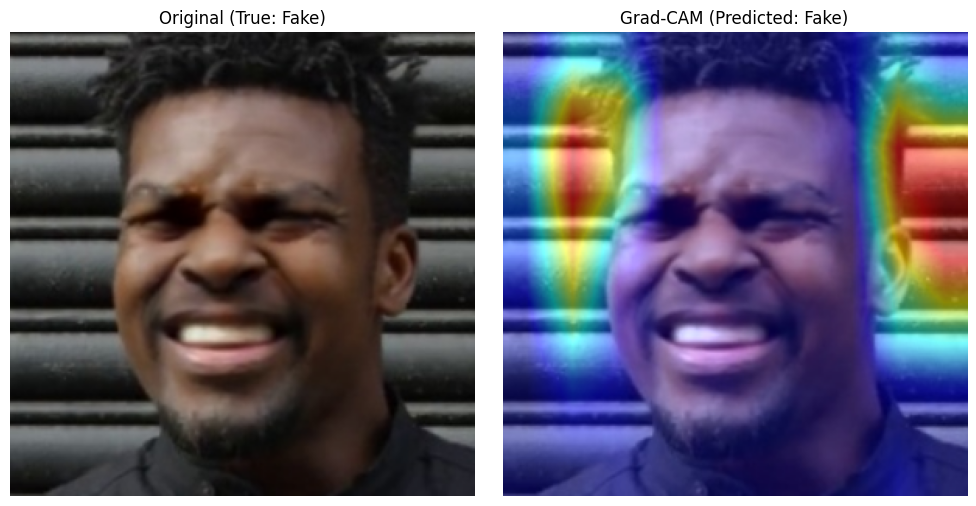

✅ Grad-CAM visualization generated successfully.


In [21]:
# ==========================================
# CELL 19: GRAD-CAM INTERPRETABILITY VISUALIZATION
# ==========================================
import torch.nn.functional as F

# Unfreeze layers for GradCAM gradient tracking
for param in model.backbone.parameters():
    param.requires_grad = True

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        # Register hooks to capture activations and gradients
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx=None):
        self.model.eval()
        model_output = self.model(input_tensor)
        
        if class_idx is None:
            class_idx = torch.argmax(model_output, dim=1).item()
            
        self.model.zero_grad()
        
        target_score = model_output[0, class_idx]
        target_score.backward(retain_graph=True)
        
        # Compute Grad-CAM weights and map
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
            
        return heatmap, class_idx

# model.backbone.block12 is the final convolutional block in Xception's exit flow
target_layer = model.backbone.block12 
cam = GradCAM(model, target_layer)

model.eval() 
sample_img, sample_label = next(iter(test_loader)) # Unseen data evaluation
sample_img_single = sample_img[0:1].to(device)

heatmap, pred_idx = cam.generate_heatmap(sample_img_single)
true_label_val = sample_label[0].item()

# --- VISUALIZATION ---
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
disp_img = inv_normalize(sample_img[0].cpu())
disp_img = disp_img.permute(1, 2, 0).numpy()
disp_img = np.clip(disp_img, 0, 1)

heatmap_resized = cv2.resize(heatmap, (299, 299))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = np.float32(heatmap_colored) / 255
heatmap_colored = heatmap_colored[..., ::-1] # BGR to RGB

overlay = heatmap_colored * 0.5 + disp_img
overlay = np.clip(overlay, 0, 1)

label_map = {0: "Real", 1: "Fake"}
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(disp_img)
axes[0].set_title(f"Original (True: {label_map[true_label_val]})")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title(f"Grad-CAM (Predicted: {label_map[pred_idx]})")
axes[1].axis('off')

plt.tight_layout()
plt.show()
print("✅ Grad-CAM visualization generated successfully.")

Starting Final Evaluation on Test Set...


Testing: 100%|██████████| 740/740 [14:33<00:00,  1.18s/it]



--- Final XceptionNet Performance ---
Accuracy:  89.35%
Precision: 86.68%
Recall:    92.99%
F1-Score:  89.73%


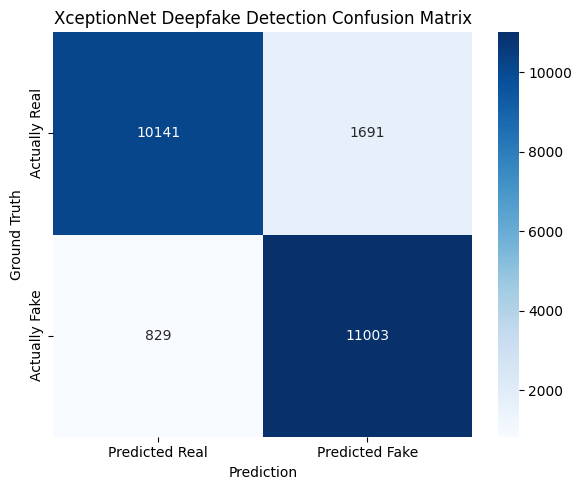

✅ Final model weights successfully saved to disk!


In [22]:
# ==========================================
# CELL 20: FINAL EVALUATION ON TEST SET
# ==========================================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import seaborn as sns

print("Starting Final Evaluation on Test Set...")

model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for inputs, labels in tqdm(test_loader, desc="Testing"):
        inputs = inputs.to(device)
        labels = labels.to(device) # FIX: Keep as 1D long tensor
        
        outputs = model(inputs)
        
        _, preds = torch.max(outputs, 1)
        
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Calculate metrics with macro/binary average safety
acc = accuracy_score(all_labels, all_preds)
prec = precision_score(all_labels, all_preds, average='binary', zero_division=0)
rec = recall_score(all_labels, all_preds, average='binary', zero_division=0)
f1 = f1_score(all_labels, all_preds, average='binary', zero_division=0)

print("\n--- Final XceptionNet Performance ---")
print(f"Accuracy:  {acc * 100:.2f}%")
print(f"Precision: {prec * 100:.2f}%")
print(f"Recall:    {rec * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

# Plot Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Predicted Real', 'Predicted Fake'], 
            yticklabels=['Actually Real', 'Actually Fake'])
plt.title('XceptionNet Deepfake Detection Confusion Matrix')
plt.xlabel('Prediction')
plt.ylabel('Ground Truth')
plt.tight_layout()
plt.show()

# Save final weights
torch.save(model.state_dict(), '/kaggle/working/xception_deepfake_detector_final.pth')
print("✅ Final model weights successfully saved to disk!")

In [23]:
# ==========================================
# CELL 21: FINAL ART ROBUSTNESS EVALUATION
# ==========================================
model.eval()
test_clean_correct = test_adv_correct = test_total = 0
test_clean_loss = test_adv_loss = 0.0

for xb, yb in tqdm(test_loader, desc="PyTorch FGSM final test", leave=True):
    xb = xb.to(device, non_blocking=True)
    yb_device = yb.to(device).long() # Keep as 1D long tensor
    
    # Final attack is explicitly 1/255 in pixel space, independent of last training epsilon.
    x_adv = custom_pytorch_fgsm(model, xb, yb_device, ART_TARGET_EPS_PIXELS)

    with torch.no_grad():
        z_clean = model(xb)
        z_adv = model(x_adv)
        
        clean_loss_val = criterion(z_clean, yb_device).item()
        adv_loss_val = criterion(z_adv, yb_device).item()
        
        _, clean_preds = torch.max(z_clean, 1)
        _, adv_preds = torch.max(z_adv, 1)
        
        test_clean_correct += torch.sum(clean_preds == yb_device).item()
        test_adv_correct += torch.sum(adv_preds == yb_device).item()
        
        test_clean_loss += clean_loss_val * xb.size(0)
        test_adv_loss += adv_loss_val * xb.size(0)
        test_total += xb.size(0)

print("\n=== Final Xception + Custom PyTorch FGSM Robustness Report ===")
print(f"Test samples evaluated: {test_total}")
print(f"Clean accuracy: {100.0 * test_clean_correct / max(test_total, 1):.2f}%")
print(f"PyTorch FGSM adversarial accuracy (epsilon exactly 1/255 pixel L-inf): {100.0 * test_adv_correct / max(test_total, 1):.2f}%")
print(f"Clean CrossEntropy loss: {test_clean_loss / max(test_total, 1):.4f}")
print(f"PyTorch FGSM CrossEntropy loss: {test_adv_loss / max(test_total, 1):.4f}")

gc.collect()
torch.cuda.empty_cache()

FINAL_ART_MODEL_PATH = "/kaggle/working/xception_deepfake_detector_art_fgsm_final.pth"
torch.save(model.state_dict(), FINAL_ART_MODEL_PATH)
print(f"✅ Final robust FGSM model successfully saved to: {FINAL_ART_MODEL_PATH}")

PyTorch FGSM final test: 100%|██████████| 740/740 [14:32<00:00,  1.18s/it]



=== Final Xception + Custom PyTorch FGSM Robustness Report ===
Test samples evaluated: 23664
Clean accuracy: 89.35%
PyTorch FGSM adversarial accuracy (epsilon exactly 1/255 pixel L-inf): 87.58%
Clean CrossEntropy loss: 0.2530
PyTorch FGSM CrossEntropy loss: 0.3975
✅ Final robust FGSM model successfully saved to: /kaggle/working/xception_deepfake_detector_art_fgsm_final.pth


In [24]:
# ==========================================
# CELL 22: EVALUATION SETUP & ACCEPTANCE THRESHOLDS
# ==========================================
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)
from scipy import stats
import json, os, time, copy, numpy as np, torch

RESULT_DIR = "/kaggle/working/xception_art_fgsm_results"
os.makedirs(RESULT_DIR, exist_ok=True)

EPS_PIXELS = [1.0/255.0, 2.0/255.0, 4.0/255.0, 8.0/255.0]
EPS_LABELS = ["1/255", "2/255", "4/255", "8/255"]

# Thresholds fixed before reading final test metrics:
ACCEPTANCE_THRESHOLDS = {
    "C1_clean_accuracy_drop_max_pp": 3.0,
    "C2_validation_adv_accuracy_min_percent": 50.0,
    "C3_validation_adv_gain_min_pp": 2.0,
    "C7_min_sensitivity_percent": 80.0,
    "C7_min_specificity_percent": 80.0,
}

print("Pre-registered criteria:", ACCEPTANCE_THRESHOLDS)
print("Evaluation epsilon values (pixel-space):", EPS_LABELS)

# Preserve exact clean-trained and ART-trained weights in memory.
if "clean_seed_weights" not in globals():
    raise RuntimeError("Clean-trained checkpoint snapshot is missing; cannot fairly compare baseline and ART model.")

CLEAN_STATE = copy.deepcopy(clean_seed_weights)
ART_STATE = copy.deepcopy(model.state_dict())

# Verify split path disjointness from the actual datasets used by this notebook.
train_paths = set(train_dataset.image_paths) if hasattr(train_dataset, 'image_paths') else set()
val_paths = set(val_dataset.image_paths) if hasattr(val_dataset, 'image_paths') else set()
test_paths = set(test_dataset.image_paths) if hasattr(test_dataset, 'image_paths') else set()

split_overlaps = {
    "train_val": len(train_paths & val_paths),
    "train_test": len(train_paths & test_paths),
    "val_test": len(val_paths & test_paths),
}
DATA_LEAKAGE_CHECK = (sum(split_overlaps.values()) == 0)
print("Split path overlaps:", split_overlaps, "| No overlap:", DATA_LEAKAGE_CHECK)

Pre-registered criteria: {'C1_clean_accuracy_drop_max_pp': 3.0, 'C2_validation_adv_accuracy_min_percent': 50.0, 'C3_validation_adv_gain_min_pp': 2.0, 'C7_min_sensitivity_percent': 80.0, 'C7_min_specificity_percent': 80.0}
Evaluation epsilon values (pixel-space): ['1/255', '2/255', '4/255', '8/255']
Split path overlaps: {'train_val': 0, 'train_test': 0, 'val_test': 0} | No overlap: True


In [25]:
# ==========================================
# CELL 23: VALIDATION CHECK FOR C1-C3 THRESHOLDS
# ==========================================
def _make_adv_batch(xb, yb, eps_pixel):
    return custom_pytorch_fgsm(model, xb, yb, eps_pixel)

def _collect_predictions(state, loader, eps_pixel=0.0, desc="Evaluation"):
    model.load_state_dict({k: v.to(device) for k, v in state.items()})
    model.eval()
    ys, probs, losses = [], [], []
    
    for xb, yb in tqdm(loader, desc=desc):
        xb = xb.to(device, non_blocking=True)
        yb = yb.to(device).long() # Keep as 1D long tensor
        
        # Generate adversarial batch using custom PyTorch input gradients
        xa = _make_adv_batch(xb, yb, eps_pixel)
        
        with torch.no_grad():
            logits = model(xa) # Shape: [batch_size, 2]
            loss = criterion(logits, yb)
            
            softmax_probs = torch.softmax(logits, dim=1)
            pr_fake = softmax_probs[:, 1] # Probability of being Fake
            
        ys.extend(yb.cpu().numpy().tolist())
        probs.extend(pr_fake.cpu().numpy().tolist())
        losses.append(float(loss.item()) * len(yb))
            
    return np.asarray(ys, dtype=int), np.asarray(probs, dtype=float), sum(losses)/max(len(ys), 1)

def _metric_row(y, p, model_name, eps_label, eps_pixel, loss):
    pred = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    specificity = tn / max(tn + fp, 1)
    sensitivity = tp / max(tp + fn, 1)
    try: 
        auc = roc_auc_score(y, p)
    except ValueError: 
        auc = np.nan
        
    return {
        "model": model_name, "epsilon": eps_label, "epsilon_pixel": eps_pixel,
        "accuracy": accuracy_score(y, pred), "precision": precision_score(y, pred, zero_division=0),
        "recall_sensitivity": recall_score(y, pred, zero_division=0),
        "f1": f1_score(y, pred, zero_division=0), "roc_auc": auc,
        "FPR": fp / max(fp + tn, 1), "FNR": fn / max(fn + tp, 1),
        "specificity": specificity, "sensitivity": sensitivity, "loss": loss,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "finite_probabilities": bool(np.isfinite(p).all()),
    }

val_1_results = {}
for name, state in [("Clean-trained", CLEAN_STATE), ("FGSM-trained", ART_STATE)]:
    yv, pv, lv = _collect_predictions(state, val_loader, 1/255, f"{name} validation 1/255")
    val_1_results[name] = _metric_row(yv, pv, name, "1/255", 1/255, lv)
    print(f"✅ {name} validation 1/255 accuracy: {100 * val_1_results[name]['accuracy']:.2f}%")

Clean-trained validation 1/255: 100%|██████████| 771/771 [11:25<00:00,  1.12it/s]


✅ Clean-trained validation 1/255 accuracy: 0.13%


FGSM-trained validation 1/255: 100%|██████████| 771/771 [11:19<00:00,  1.13it/s]

✅ FGSM-trained validation 1/255 accuracy: 88.21%


In [26]:
# ==========================================
# CELL 24: FINAL MULTI-EPSILON TEST SWEEP (WITH VRAM FLUSH)
# ==========================================
test_rows, test_predictions = [], {}
eval_start = time.time()

for model_name, state in [("Clean-trained", CLEAN_STATE), ("FGSM-trained", ART_STATE)]:
    for eps_pixel, eps_label in zip(EPS_PIXELS, EPS_LABELS):
        y, prob, loss = _collect_predictions(
            state, test_loader, eps_pixel,
            f"TEST {model_name} epsilon {eps_label}"
        )
        row = _metric_row(y, prob, model_name, eps_label, eps_pixel, loss)
        test_rows.append(row)
        test_predictions[(model_name, eps_label)] = (y, prob)
        
        print(f"{model_name:14s} eps={eps_label:7s} acc={row['accuracy']*100:6.2f}% "
              f"F1={row['f1']*100:6.2f}% AUC={row['roc_auc']:.4f}")
        
        # Clear dangling tensors and free GPU cache after each epsilon evaluation
        gc.collect()
        torch.cuda.empty_cache()

test_df = pd.DataFrame(test_rows)
test_df.to_csv(os.path.join(RESULT_DIR, "all_test_metrics.csv"), index=False)
print(f"✅ Test sweep elapsed: {(time.time() - eval_start) / 3600:.2f} hours")

TEST Clean-trained epsilon 1/255: 100%|██████████| 740/740 [10:52<00:00,  1.13it/s]


Clean-trained  eps=1/255   acc=  0.10% F1=  0.08% AUC=0.0000


TEST Clean-trained epsilon 2/255: 100%|██████████| 740/740 [10:53<00:00,  1.13it/s]


Clean-trained  eps=2/255   acc=  0.21% F1=  0.07% AUC=0.0000


TEST Clean-trained epsilon 4/255: 100%|██████████| 740/740 [10:50<00:00,  1.14it/s]


Clean-trained  eps=4/255   acc=  0.94% F1=  0.72% AUC=0.0006


... (6 outputs left out)

TEST FGSM-trained epsilon 4/255: 100%|██████████| 740/740 [10:52<00:00,  1.13it/s]


FGSM-trained   eps=4/255   acc= 95.68% F1= 95.61% AUC=0.9915


TEST FGSM-trained epsilon 8/255: 100%|██████████| 740/740 [10:53<00:00,  1.13it/s]


FGSM-trained   eps=8/255   acc= 92.53% F1= 92.26% AUC=0.9804
✅ Test sweep elapsed: 1.45 hours


TABLE 1 — Clean-trained Xception


,epsilon,accuracy,precision,recall_sensitivity,f1,roc_auc,FPR,FNR,specificity,sensitivity,loss
0,1/255,0.0010,0.0008,0.0008,0.0008,0.0000,0.9987,0.9992,0.0013,0.0008,12.6698
1,2/255,0.0021,0.0007,0.0007,0.0007,0.0000,0.9965,0.9993,0.0035,0.0007,11.6879
2,4/255,0.0094,0.0072,0.0072,0.0072,0.0006,0.9884,0.9928,0.0116,0.0072,8.9555
3,8/255,0.0750,0.1100,0.1199,0.1148,0.0154,0.9699,0.8801,0.0301,0.1199,5.2993


TABLE 2 — ART-FGSM-trained Xception


,epsilon,accuracy,precision,recall_sensitivity,f1,roc_auc,FPR,FNR,specificity,sensitivity,loss
4,1/255,0.8758,0.9416,0.8014,0.8659,0.9553,0.0497,0.1986,0.9503,0.8014,0.3975
5,2/255,0.9577,0.9768,0.9378,0.9569,0.9910,0.0223,0.0622,0.9777,0.9378,0.1451
6,4/255,0.9568,0.9719,0.9408,0.9561,0.9915,0.0272,0.0592,0.9728,0.9408,0.1258
7,8/255,0.9253,0.9582,0.8895,0.9226,0.9804,0.0388,0.1105,0.9612,0.8895,0.1909


TABLE 4 — ROC-AUC comparison


model,epsilon,Clean-trained,FGSM-trained
0,1/255,0.0000,0.9553
1,2/255,0.0000,0.9910
2,4/255,0.0006,0.9915
3,8/255,0.0154,0.9804


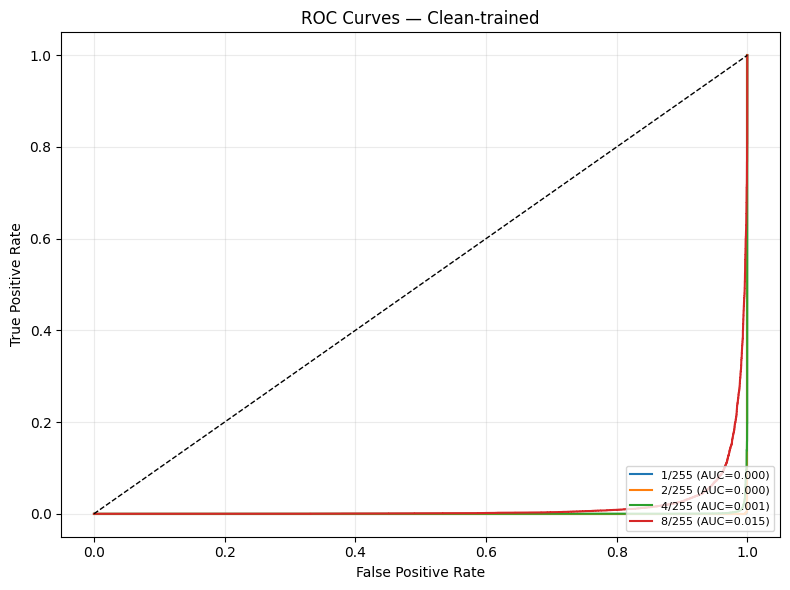

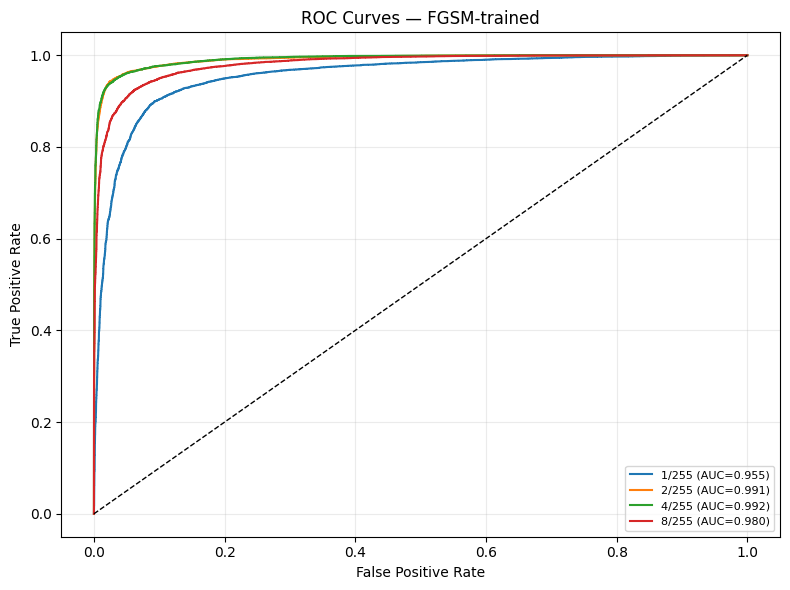

✅ Result tables and ROC curves generated successfully.


In [27]:
# ==========================================
# CELL 25: RESULT TABLES AND ROC CURVES
# ==========================================
metric_cols = ["epsilon", "accuracy", "precision", "recall_sensitivity", "f1", "roc_auc",
               "FPR", "FNR", "specificity", "sensitivity", "loss"]

table1 = test_df[test_df.model == "Clean-trained"][metric_cols].copy()
table2 = test_df[test_df.model == "FGSM-trained"][metric_cols].copy()
table4 = test_df.pivot(index="epsilon", columns="model", values="roc_auc").reset_index()

for df in (table1, table2, table4):
    for col in df.columns:
        if col not in ("epsilon", "model") and pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].round(4)

print("TABLE 1 — Clean-trained Xception")
display(table1)

print("TABLE 2 — ART-FGSM-trained Xception")
display(table2)

print("TABLE 4 — ROC-AUC comparison")
display(table4)

table1.to_csv(os.path.join(RESULT_DIR, "table1_clean_trained.csv"), index=False)
table2.to_csv(os.path.join(RESULT_DIR, "table2_fgsm_trained.csv"), index=False)
table4.to_csv(os.path.join(RESULT_DIR, "table4_roc_auc.csv"), index=False)

# ROC curves using continuous probability outputs
for model_name in ["Clean-trained", "FGSM-trained"]:
    plt.figure(figsize=(8, 6))
    for eps_label in EPS_LABELS:
        y, prob = test_predictions[(model_name, eps_label)]
        fpr, tpr, _ = roc_curve(y, prob)
        auc = roc_auc_score(y, prob)
        plt.plot(fpr, tpr, label=f"{eps_label} (AUC={auc:.3f})")
        
    plt.plot([0, 1], [0, 1], "k--", linewidth=1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curves — {model_name}")
    plt.legend(loc="lower right", fontsize=8)
    plt.grid(alpha=0.25)
    plt.tight_layout()
    
    plt.savefig(os.path.join(RESULT_DIR, f"roc_{model_name.lower().replace('-', '_')}.png"), dpi=300)
    plt.show()

print("✅ Result tables and ROC curves generated successfully.")

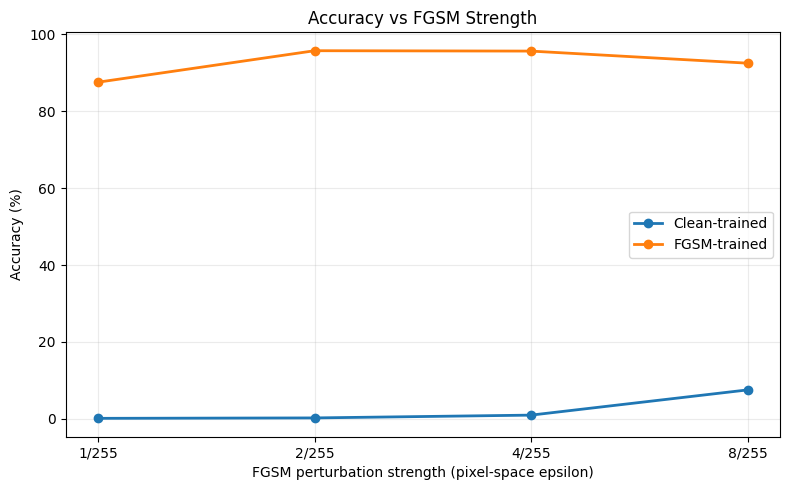

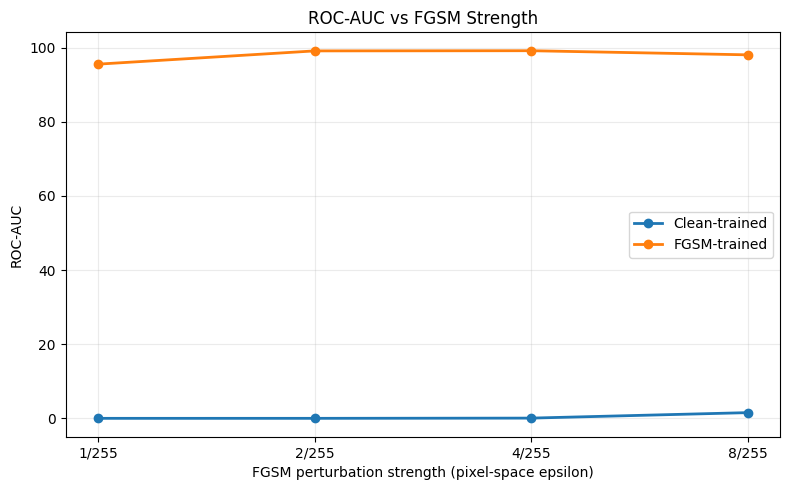

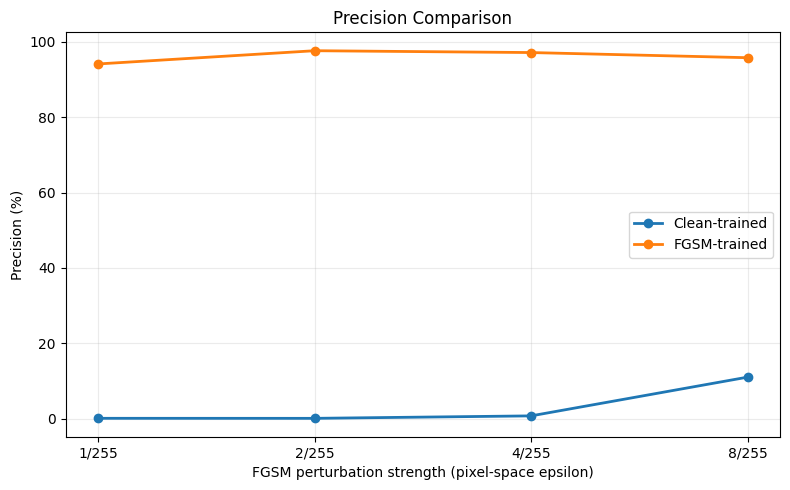

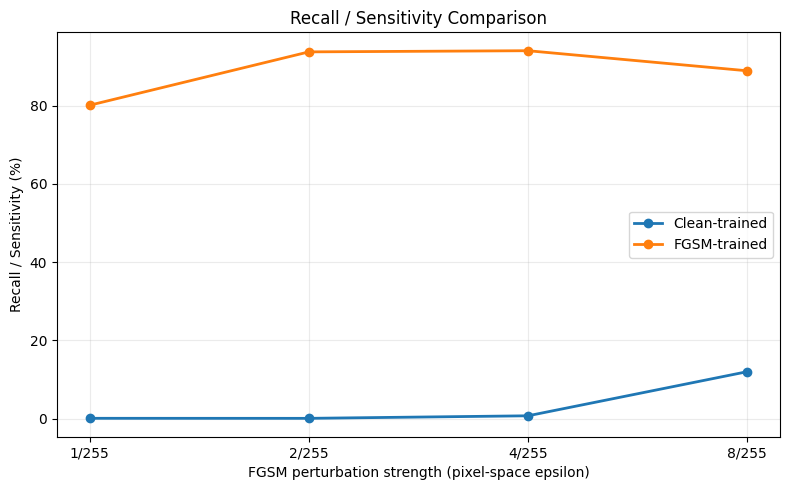

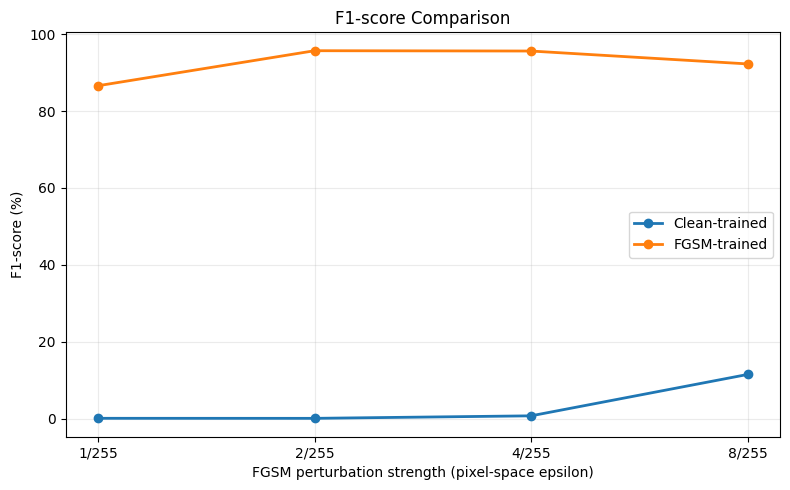

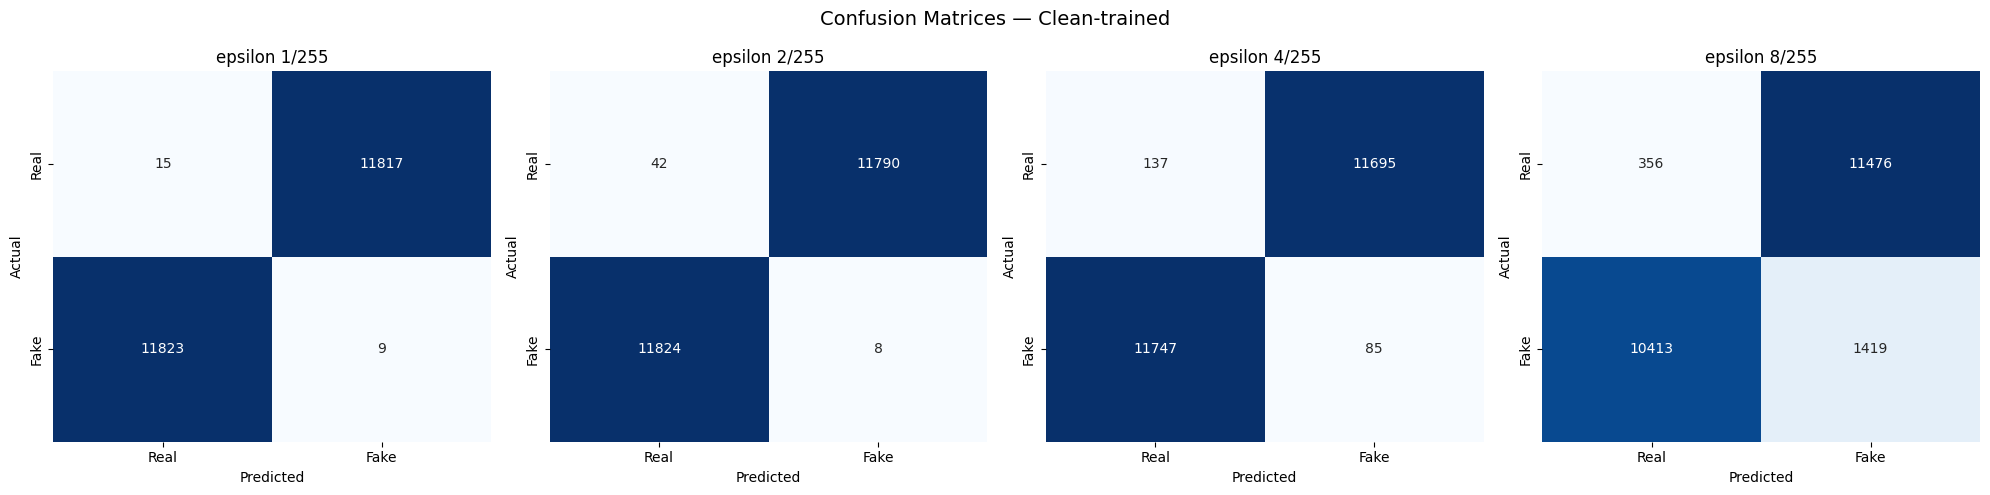

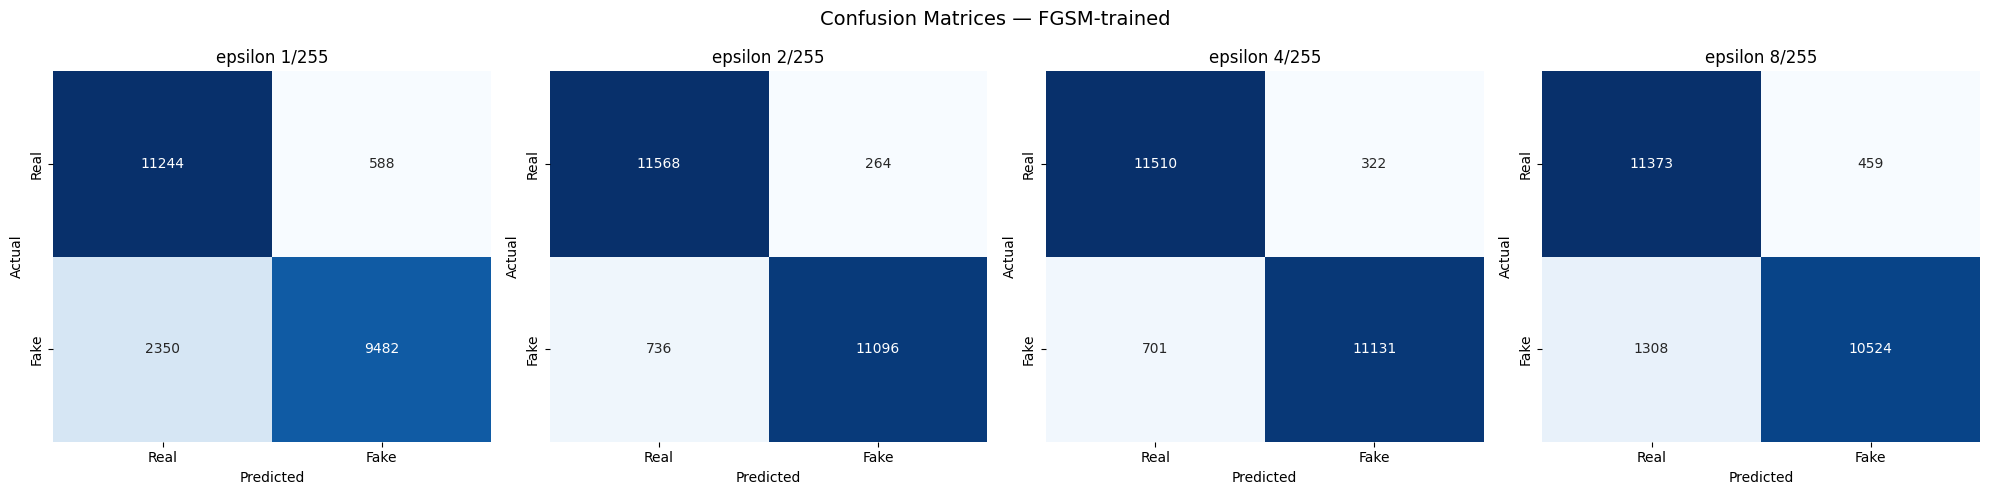

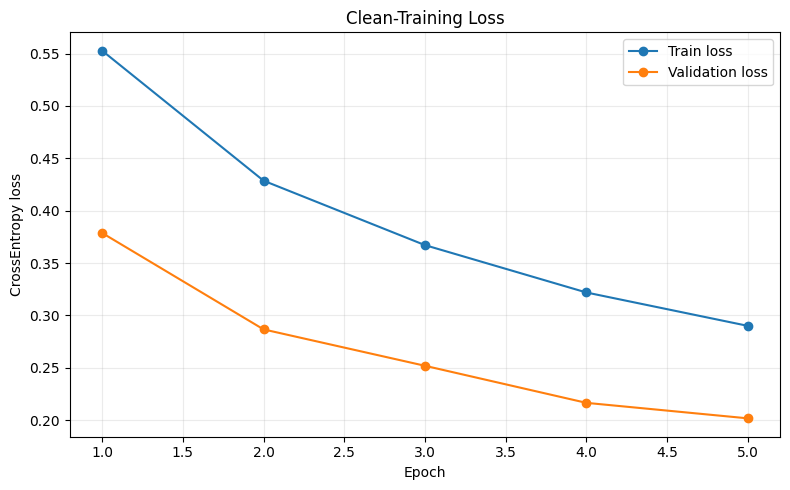

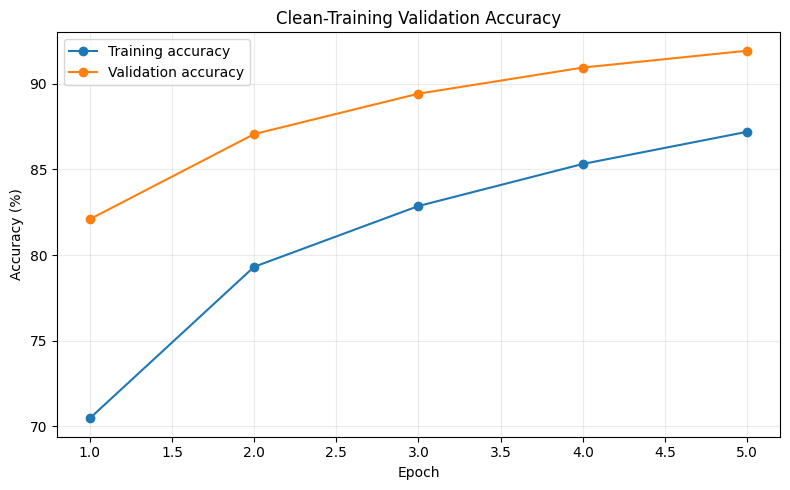

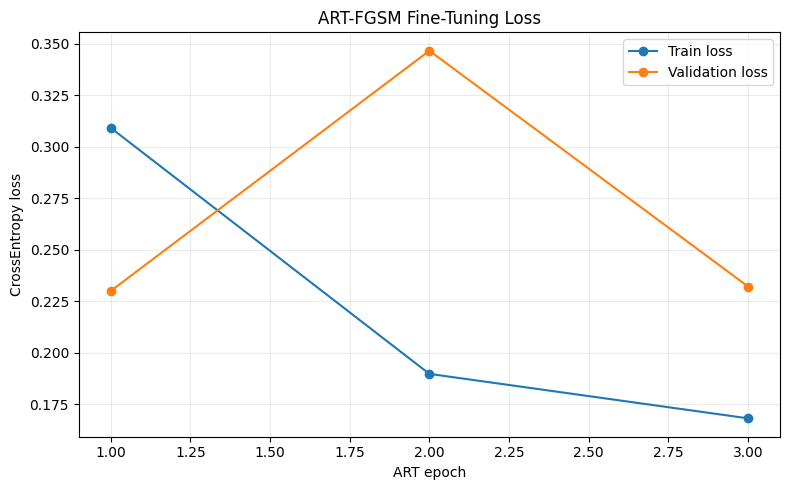

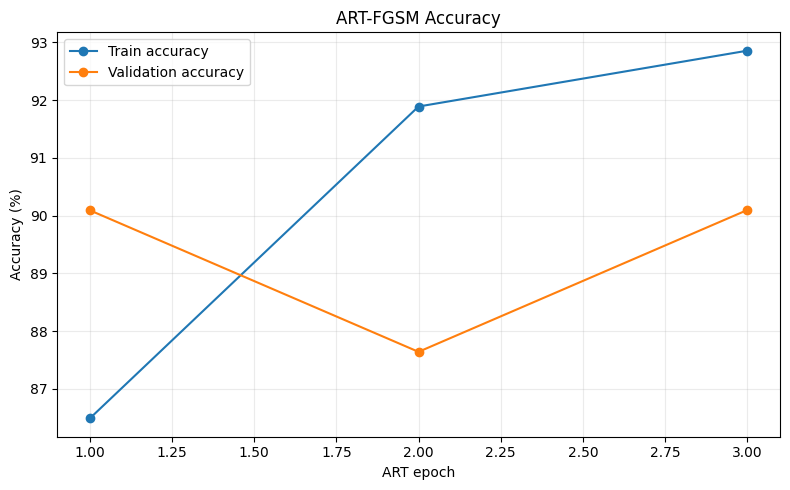

✅ All plots and visualization charts generated successfully!


In [28]:
# ==========================================
# CELL 26: VISUAL COMPARISONS & TRAINING CURVES
# ==========================================
def _plot_metric(metric, ylabel, title, filename):
    plt.figure(figsize=(8, 5))
    for model_name in ["Clean-trained", "FGSM-trained"]:
        d = test_df[test_df.model == model_name]
        plt.plot(d.epsilon, 100 * d[metric], marker="o", linewidth=2, label=model_name)
    plt.xlabel("FGSM perturbation strength (pixel-space epsilon)")
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(alpha=0.25)
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, filename), dpi=300)
    plt.show()

_plot_metric("accuracy", "Accuracy (%)", "Accuracy vs FGSM Strength", "accuracy_vs_epsilon.png")
_plot_metric("roc_auc", "ROC-AUC", "ROC-AUC vs FGSM Strength", "roc_auc_vs_epsilon.png")

for metric, label in [("precision", "Precision"), ("recall_sensitivity", "Recall / Sensitivity"), ("f1", "F1-score")]:
    _plot_metric(metric, f"{label} (%)", f"{label} Comparison", f"comparison_{metric}.png")

# Confusion matrix grids across epsilon budgets
for model_name in ["Clean-trained", "FGSM-trained"]:
    fig, axes = plt.subplots(1, 4, figsize=(20, 5)) # Adjusted layout for 4 epsilon levels (1/255, 2/255, 4/255, 8/255)
    for ax, eps_label in zip(axes.flat, EPS_LABELS):
        y, prob = test_predictions[(model_name, eps_label)]
        cm = confusion_matrix(y, (prob >= 0.5).astype(int), labels=[0, 1])
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                    xticklabels=["Real", "Fake"], yticklabels=["Real", "Fake"])
        ax.set_title(f"epsilon {eps_label}")
        ax.set_xlabel("Predicted")
        ax.set_ylabel("Actual")
    fig.suptitle(f"Confusion Matrices — {model_name}", fontsize=14)
    fig.tight_layout()
    fig.savefig(os.path.join(RESULT_DIR, f"confusion_matrices_{model_name.lower().replace('-', '_')}.png"), dpi=300)
    plt.show()

# Training curves: clean-training history and ART fine-tuning history
if "CLEAN_HISTORY" in globals() and len(CLEAN_HISTORY):
    ch = pd.DataFrame(CLEAN_HISTORY)
    plt.figure(figsize=(8, 5))
    plt.plot(ch.epoch, ch.train_loss, marker="o", label="Train loss")
    plt.plot(ch.epoch, ch.val_loss, marker="o", label="Validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("CrossEntropy loss")
    plt.title("Clean-Training Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, "clean_training_loss.png"), dpi=300)
    plt.show()
    
    plt.figure(figsize=(8, 5))
    plt.plot(ch.epoch, ch.train_accuracy_percent, marker="o", label="Training accuracy")
    plt.plot(ch.epoch, ch.val_accuracy_percent, marker="o", label="Validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("Clean-Training Validation Accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, "clean_training_accuracy.png"), dpi=300)
    plt.show()

if "ART_HISTORY" in globals() and len(ART_HISTORY):
    ah = pd.DataFrame(ART_HISTORY)
    plt.figure(figsize=(8, 5))
    plt.plot(ah.epoch, ah.train_loss, marker="o", label="Train loss")
    plt.plot(ah.epoch, ah.val_loss, marker="o", label="Validation loss")
    plt.xlabel("ART epoch")
    plt.ylabel("CrossEntropy loss")
    plt.title("ART-FGSM Fine-Tuning Loss")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, "art_training_loss.png"), dpi=300)
    plt.show()
    
    plt.figure(figsize=(8, 5))
    if "train_accuracy_percent" in ah:
        plt.plot(ah.epoch, ah.train_accuracy_percent, marker="o", label="Train accuracy")
    plt.plot(ah.epoch, ah.val_accuracy_percent, marker="o", label="Validation accuracy")
    plt.xlabel("ART epoch")
    plt.ylabel("Accuracy (%)")
    plt.title("ART-FGSM Accuracy")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULT_DIR, "art_training_accuracy.png"), dpi=300)
    plt.show()

print("✅ All plots and visualization charts generated successfully!")

In [29]:
# ==========================================
# CELL 27: EXPORT CONSOLIDATED EXPERIMENT ARTIFACTS
# ==========================================
model.load_state_dict(ART_STATE)
FINAL_ART_MODEL_PATH = os.path.join(RESULT_DIR, "xception_art_fgsm_final.pth")
CLEAN_MODEL_PATH = os.path.join(RESULT_DIR, "xception_clean_baseline.pth")

torch.save(ART_STATE, FINAL_ART_MODEL_PATH)
torch.save(CLEAN_STATE, CLEAN_MODEL_PATH)

if "ART_HISTORY" in globals() and ART_HISTORY:
    pd.DataFrame(ART_HISTORY).to_csv(os.path.join(RESULT_DIR, "art_training_history.csv"), index=False)

if "CLEAN_HISTORY" in globals() and CLEAN_HISTORY:
    pd.DataFrame(CLEAN_HISTORY).to_csv(os.path.join(RESULT_DIR, "clean_training_history.csv"), index=False)

print(f"✅ All result files saved under: {RESULT_DIR}")
print("Saved files:", sorted(os.listdir(RESULT_DIR)))

✅ All result files saved under: /kaggle/working/xception_art_fgsm_results
Saved files: ['accuracy_vs_epsilon.png', 'all_test_metrics.csv', 'art_training_accuracy.png', 'art_training_history.csv', 'art_training_loss.png', 'clean_training_accuracy.png', 'clean_training_history.csv', 'clean_training_loss.png', 'comparison_f1.png', 'comparison_precision.png', 'comparison_recall_sensitivity.png', 'confusion_matrices_clean_trained.png', 'confusion_matrices_fgsm_trained.png', 'roc_auc_vs_epsilon.png', 'roc_clean_trained.png', 'roc_fgsm_trained.png', 'table1_clean_trained.csv', 'table2_fgsm_trained.csv', 'table4_roc_auc.csv', 'xception_art_fgsm_final.pth', 'xception_clean_baseline.pth']
